In [32]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [33]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

#Armazena nosso arquivo base em formato csv na variável df "DataFrame", recurso da biblioteca Pandas
df = pd.read_csv('/content/drive/MyDrive/Comunicação & Redes Q2.2026/Lista de arestas.csv', header=0)
print(df.to_string()) #Printa no terminal todas as linhas da tabela CSV

#Cria um grafo a partir do arquivo base armazenado na variável df
G = nx.from_pandas_edgelist(
    df,
    source='Origem',
    target='Destino',
    create_using=nx.DiGraph() #"DiGraph" - Grafo direcionado
)



    Origem  Destino Direcionado
0        1        2        True
1        1        5        True
2        1       23        True
3       20        1        True
4       21        1        True
5       18        1        True
6       19        1        True
7        2        3        True
8        2        4        True
9        2       22        True
10       5        6        True
11       5        7        True
12       5        8        True
13       5        9        True
14       5       10        True
15       5       11        True
16       5       12        True
17       5       13       False
18      13        5      False 
19       5       14       False
20      14        5      False 
21       5       15       False
22      15        5      False 
23       5       18       False
24      18        5      False 
25      20        5       False
26       5       20      False 
27       5       22        True
28       5       23       False
29      23        5      False 
30      

REDE PROTEÇÃO ESPECIAL DA ASSISTÊNCIA SOCIAL DE DIADEMA

Ordem da rede (número de órgãos):  29

Tamanho da rede:  67

Coeficiente de agrupamento médio:  0.2745358473036336

Densidade da rede:  0.08251231527093596


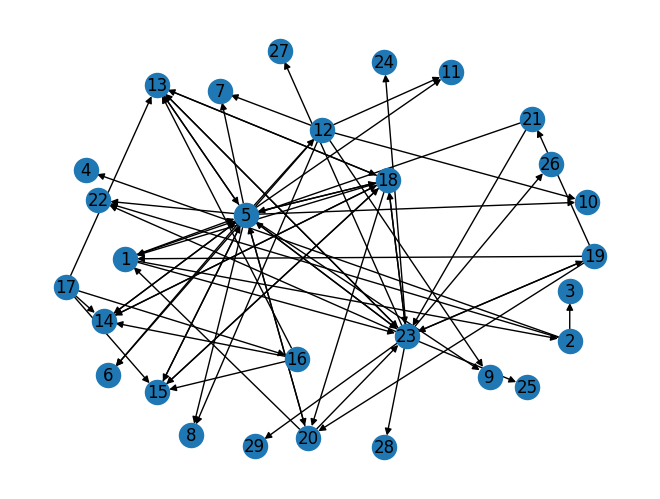

In [34]:
print("REDE PROTEÇÃO ESPECIAL DA ASSISTÊNCIA SOCIAL DE DIADEMA\n")
ordem = G.number_of_nodes()
tamanho = G.number_of_edges()
Avg_CoefAgrupamento = nx.average_clustering(G)
densidade = nx.density(G)

#print(G) - printa no terminal que é um grafo direcional (DiGraph) com X nós e Y arestas
#print(G.degree) - printa no terminal (nó, grau do nó)

#printa os parâmetros calculados
print("Ordem da rede (número de órgãos): ", ordem)
print("\nTamanho da rede: ", tamanho)
print("\nCoeficiente de agrupamento médio: ", Avg_CoefAgrupamento)
print("\nDensidade da rede: ", densidade)

#plota a rede analisada
pos = nx.spring_layout(G, k=2) #k>1 facilita a visualização
nx.draw(G, pos, with_labels=True)
plt.show()

REDE ALEATÓRIA ERDOS RENYI CRIADA COM BASE NA REDE ORIGINAL
Ordem da rede (número de órgãos):  29

Tamanho da rede:  71

Coeficiente de agrupamento médio:  0.07476737821565407

Densidade da rede:  0.0874384236453202


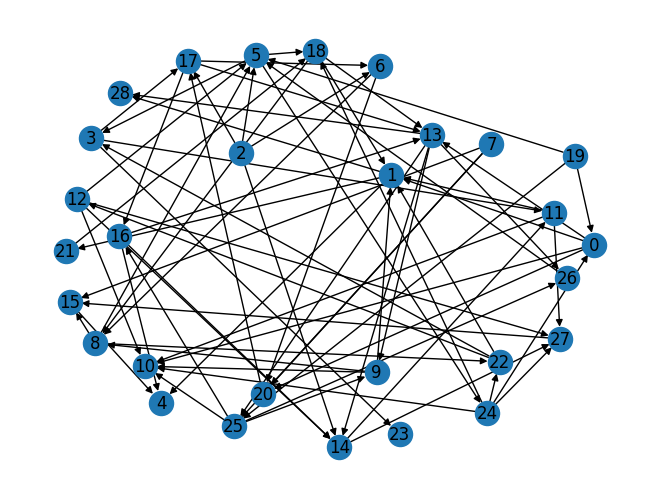

In [35]:
#Cria uma rede aleatória de mesma ordem e tamanho utilizando o método de erdos renyi
print("REDE ALEATÓRIA ERDOS RENYI CRIADA COM BASE NA REDE ORIGINAL")
G_aleatoria = nx.erdos_renyi_graph(ordem, densidade, directed=True, create_using=nx.DiGraph)

ordem_aleatoria = G_aleatoria.number_of_nodes()
tamanho_aleatoria = G_aleatoria.number_of_edges()
Avg_CoefAgrupamento_aleatoria = nx.average_clustering(G_aleatoria)
densidade_aleatoria = nx.density(G_aleatoria)

#print(G) - printa no terminal que é um grafo direcional (DiGraph) com X nós e Y arestas
#print(G.degree) - printa no terminal (nó, grau do nó)

#printa os parâmetros calculados
print("Ordem da rede (número de órgãos): ", ordem_aleatoria)
print("\nTamanho da rede: ", tamanho_aleatoria)
print("\nCoeficiente de agrupamento médio: ", Avg_CoefAgrupamento_aleatoria)
print("\nDensidade da rede: ", densidade_aleatoria)

#plota a rede analisada
pos_aleatoria = nx.spring_layout(G_aleatoria, k=2) #k>1 facilita a visualização
nx.draw(G_aleatoria, pos_aleatoria, with_labels=True)
plt.show()

REDE DE PEQUENO MUNDO DE MESMA ORDEM DO GRAFO OBJETO DE ESTUDO

Ordem da rede (número de órgãos):  29

Tamanho da rede:  58

Coeficiente de agrupamento médio:  0.3333333333333333

Densidade da rede:  0.14285714285714285


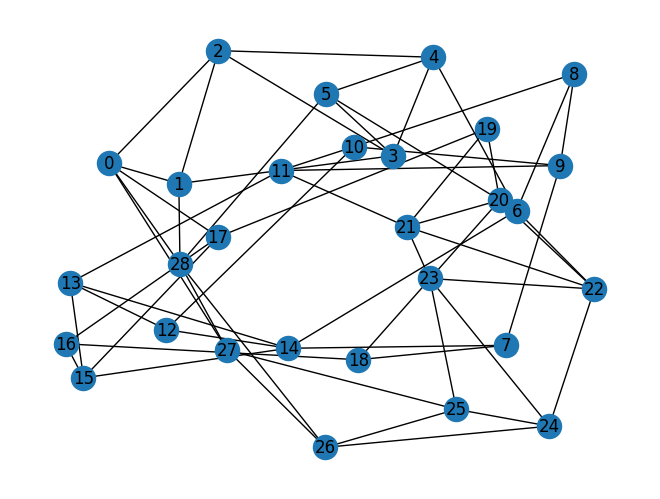

In [36]:
#EXTRAS: REDE DE PEQUENO MUNDO
#Criando rede de mundo pequeno e calculando mesmos parâmetros
print("REDE DE PEQUENO MUNDO DE MESMA ORDEM DO GRAFO OBJETO DE ESTUDO\n")
SmallG = nx.watts_strogatz_graph(ordem, 4, densidade)

ordem_small = SmallG.number_of_nodes()
tamanho_small = SmallG.number_of_edges()
Avg_CoefAgrupamento_small = nx.average_clustering(SmallG)
densidade_small = nx.density(SmallG)

#print(G) - printa no terminal que é um grafo direcional (DiGraph) com X nós e Y arestas
#print(G.degree) - printa no terminal (nó, grau do nó)

#printa os parâmetros calculados
print("Ordem da rede (número de órgãos): ", ordem_small)
print("\nTamanho da rede: ", tamanho_small)
print("\nCoeficiente de agrupamento médio: ", Avg_CoefAgrupamento_small)
print("\nDensidade da rede: ", densidade_small)

pos_Small = nx.spring_layout(SmallG, k=1) #k>=1 facilita a visualização
nx.draw(SmallG, pos_Small, with_labels=True)
plt.show()

In [37]:
#EXTRAS: DIAMETRO E GRAU DE SEPARAÇÃO MÉDIO
G_undirected = G.to_undirected()
diametroG = nx.diameter(G_undirected)
G_undirected_aleatoria = G_aleatoria.to_undirected()
diametroRandom = nx.diameter(G_undirected_aleatoria)
G_undirected_small = SmallG.to_undirected()
diametroSmall = nx.diameter(G_undirected_small)

print("Diâmetro da Rede: ", diametroG)
print("Diâmetro da Rede Aleatória: ", diametroRandom)
print("Diâmetro da Rede de Pequeno Mundo: ", diametroSmall)

separacao_media = nx.average_shortest_path_length(G_undirected)
separacao_media_aleatoria = nx.average_shortest_path_length(G_undirected_aleatoria)
separacao_media_small = nx.average_shortest_path_length(G_undirected_small)

print("Grau de Separação Médio da Rede: ", separacao_media)
print("Grau de Separação Médio da Rede Aleatória: ", separacao_media_aleatoria)
print("Grau de Separação Médio da Rede de Pequeno Mundo: ", separacao_media_small)

Diâmetro da Rede:  5
Diâmetro da Rede Aleatória:  4
Diâmetro da Rede de Pequeno Mundo:  5
Grau de Separação Médio da Rede:  2.396551724137931
Grau de Separação Médio da Rede Aleatória:  2.1699507389162562
Grau de Separação Médio da Rede de Pequeno Mundo:  2.8078817733990147
